In [27]:
import os

base_dir = r"G:\ASD Without Image\ASD Vedio"
data_dir = os.path.join(base_dir, "New Voice Data")
output_dir = os.path.join(base_dir, "updated voice data")

print("Data folder:", data_dir)
print("Output folder:", output_dir)


Data folder: G:\ASD Without Image\ASD Vedio\New Voice Data
Output folder: G:\ASD Without Image\ASD Vedio\updated voice data


In [28]:
import os

os.makedirs(os.path.join(output_dir, "autism"), exist_ok=True)
os.makedirs(os.path.join(output_dir, "anomaly_non_autism"), exist_ok=True)


In [29]:
import librosa
import numpy as np

SR = 16000
N_MELS = 64
DURATION = 3.0
N_FFT = 1024
HOP_LENGTH = 256
MAX_FRAMES = 128

def load_wav(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    length = int(SR * DURATION)

    if len(y) < length:
        pad = length - len(y)
        y = np.pad(y, (0, pad))
    else:
        y = y[:length]
    return y

def wav_to_mel(y):
    mel = librosa.feature.melspectrogram(
        y=y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)

    if mel_db.shape[1] < MAX_FRAMES:
        pad = MAX_FRAMES - mel_db.shape[1]
        mel_db = np.pad(mel_db, ((0,0),(0,pad)))
    else:
        mel_db = mel_db[:, :MAX_FRAMES]
    return mel_db.astype(np.float32)


In [30]:
all_specs = []
all_paths = []

for fname in os.listdir(data_dir):
    if fname.lower().endswith(".wav"):
        path = os.path.join(data_dir, fname)
        try:
            y = load_wav(path)
            spec = wav_to_mel(y)
            all_specs.append(spec)
            all_paths.append(path)
        except Exception as e:
            print("Error:", e)

all_specs = np.stack(all_specs)
all_paths = np.array(all_paths)

print("Total autism samples:", len(all_specs))


Total autism samples: 527


In [31]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class AutismDataset(Dataset):
    def __init__(self, specs, paths):
        self.specs = specs
        self.paths = paths
        
    def __len__(self):
        return len(self.specs)
    
    def __getitem__(self, i):
        x = self.specs[i][None, :, :] 
        return torch.tensor(x), self.paths[i]

dataset = AutismDataset(all_specs, all_paths)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

class AutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1*64*128, 256),
            nn.ReLU(),
            nn.Linear(256, 64)
        )
        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 1*64*128),
            nn.Tanh()
        )
    def forward(self, x):
        z = self.encoder(x)
        y = self.decoder(z)
        return y.view(-1, 1, 64, 128)

model = AutoEncoder().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()


In [32]:
epochs = 30
for e in range(epochs):
    total_loss = 0
    for x, _ in loader:
        x = x.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = loss_fn(out, x)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {e+1}/{epochs}, Loss={total_loss/len(loader):.4f}")


Epoch 1/30, Loss=3379.5933
Epoch 2/30, Loss=3358.0788
Epoch 3/30, Loss=3356.3245
Epoch 4/30, Loss=3355.3840
Epoch 5/30, Loss=3355.0733
Epoch 6/30, Loss=3355.0760
Epoch 7/30, Loss=3355.9091
Epoch 8/30, Loss=3354.9894
Epoch 9/30, Loss=3355.3167
Epoch 10/30, Loss=3355.2292
Epoch 11/30, Loss=3355.2210
Epoch 12/30, Loss=3355.4354
Epoch 13/30, Loss=3354.9764
Epoch 14/30, Loss=3355.2451
Epoch 15/30, Loss=3355.0858
Epoch 16/30, Loss=3354.6349
Epoch 17/30, Loss=3354.9802
Epoch 18/30, Loss=3354.8540
Epoch 19/30, Loss=3355.5442
Epoch 20/30, Loss=3355.2913
Epoch 21/30, Loss=3355.1526
Epoch 22/30, Loss=3354.5818
Epoch 23/30, Loss=3355.7058
Epoch 24/30, Loss=3355.8279
Epoch 25/30, Loss=3355.1727
Epoch 26/30, Loss=3354.9012
Epoch 27/30, Loss=3354.8378
Epoch 28/30, Loss=3355.3571
Epoch 29/30, Loss=3354.7440
Epoch 30/30, Loss=3354.5755


In [33]:
import shutil
import numpy as np

model.eval()
errors = []
paths = []

with torch.no_grad():
    for x, p in loader:
        x = x.to(device)
        out = model(x)
        loss = torch.mean((out - x)**2, dim=(1,2,3)).cpu().numpy()
        errors.extend(loss)
        paths.extend(p)

errors = np.array(errors)
threshold = errors.mean() + 2 * errors.std()
print("Anomaly threshold =", threshold)


Anomaly threshold = 4778.9329833984375


In [34]:
for err, p in zip(errors, paths):
    fname = os.path.basename(p)
    if err > threshold:
        dst = os.path.join(output_dir, "anomaly_non_autism", fname)
    else:
        dst = os.path.join(output_dir, "autism", fname)
    shutil.copy2(p, dst)

print("Classification Completed!")
print("Saved in:", output_dir)


Classification Completed!
Saved in: G:\ASD Without Image\ASD Vedio\updated voice data


In [35]:
import os
import numpy as np
import librosa
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib


In [36]:
base_dir = r"G:\ASD Without Image\ASD Vedio"
data_dir = os.path.join(base_dir, "updated voice data")  # labeled data
print("Using data from:", data_dir)


Using data from: G:\ASD Without Image\ASD Vedio\updated voice data


In [37]:
SR = 16000
N_MELS = 64
DURATION = 3.0
N_FFT = 1024
HOP_LENGTH = 256
MAX_FRAMES = 128

def load_wav(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    length = int(SR * DURATION)
    if len(y) < length:
        pad = length - len(y)
        y = np.pad(y, (0, pad))
    else:
        y = y[:length]
    return y

def wav_to_mel(y):
    mel = librosa.feature.melspectrogram(
        y=y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)

    if mel_db.shape[1] < MAX_FRAMES:
        pad = MAX_FRAMES - mel_db.shape[1]
        mel_db = np.pad(mel_db, ((0,0),(0,pad)))
    else:
        mel_db = mel_db[:, :MAX_FRAMES]
    return mel_db.astype(np.float32)


In [38]:
class_names = ["autism", "anomaly_non_autism"]
class_to_idx = {name: i for i, name in enumerate(class_names)}
print("Label mapping:", class_to_idx)

X = []
y = []
paths = []

for class_name in class_names:
    class_dir = os.path.join(data_dir, class_name)
    if not os.path.isdir(class_dir):
        print("WARNING: missing folder:", class_dir)
        continue

    label = class_to_idx[class_name]
    for fname in os.listdir(class_dir):
        if not fname.lower().endswith(".wav"):
            continue
        fpath = os.path.join(class_dir, fname)
        try:
            audio = load_wav(fpath)
            mel = wav_to_mel(audio)          # (64, 128)
            feat = mel.flatten()             # (64*128 = 8192)
            X.append(feat)
            y.append(label)
            paths.append(fpath)
        except Exception as e:
            print("Error:", fpath, "->", e)

X = np.array(X)
y = np.array(y)
paths = np.array(paths)

print("Total samples:", len(X))
print("Feature dimension:", X.shape[1] if len(X) > 0 else "N/A")


Label mapping: {'autism': 0, 'anomaly_non_autism': 1}
Total samples: 527
Feature dimension: 8192


In [39]:
if len(X) == 0:
    raise ValueError("No data loaded. Check your 'updated voice data' folder structure and .wav files.")

X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X, y, paths, test_size=0.2, random_state=42, stratify=y
)

print("Train samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)


Train samples: 421
Test samples: 106


In [40]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=2000),
    "SVM_RBF": SVC(kernel='rbf', probability=True),
    "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=None, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

results = {}
best_model_name = None
best_model = None
best_acc = 0.0

for name, model in models.items():
    print(f"\nTraining model: {name}")
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"Test accuracy ({name}): {acc*100:.2f}%")
    
    if acc > best_acc:
        best_acc = acc
        best_model_name = name
        best_model = model

print("\n==============================")
print("Best model:", best_model_name)
print(f"Best accuracy: {best_acc*100:.2f}%")
print("==============================")



Training model: LogisticRegression
Test accuracy (LogisticRegression): 99.06%

Training model: SVM_RBF
Test accuracy (SVM_RBF): 100.00%

Training model: RandomForest
Test accuracy (RandomForest): 99.06%

Training model: GradientBoosting
Test accuracy (GradientBoosting): 97.17%

Training model: KNN
Test accuracy (KNN): 98.11%

Best model: SVM_RBF
Best accuracy: 100.00%


Classification report:

                    precision    recall  f1-score   support

            autism       1.00      1.00      1.00       102
anomaly_non_autism       1.00      1.00      1.00         4

          accuracy                           1.00       106
         macro avg       1.00      1.00      1.00       106
      weighted avg       1.00      1.00      1.00       106

Confusion matrix:
 [[102   0]
 [  0   4]]


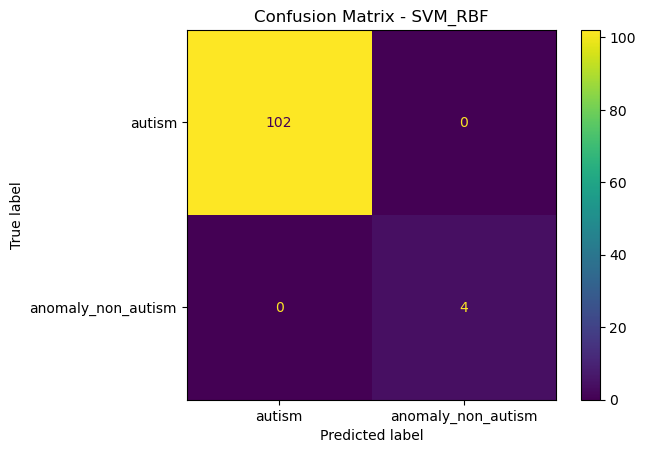

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_best_pred = best_model.predict(X_test_scaled)

print("Classification report:\n")
print(classification_report(y_test, y_best_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_best_pred)
print("Confusion matrix:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot()
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()


In [42]:
model_package = {
    "model": best_model,
    "scaler": scaler,
    "class_to_idx": class_to_idx,
    "idx_to_class": {v: k for k, v in class_to_idx.items()}
}

model_path = os.path.join(base_dir, "voice_classifier_model.joblib")
joblib.dump(model_package, model_path)

print("Model saved to:", model_path)


Model saved to: G:\ASD Without Image\ASD Vedio\voice_classifier_model.joblib


In [44]:
import joblib
import numpy as np
import librosa
import os

# === load model =========
loaded = joblib.load(r"G:\ASD Without Image\ASD Vedio\voice_classifier_model.joblib")
model = loaded["model"]
scaler = loaded["scaler"]
idx_to_class = loaded["idx_to_class"]

# same feature functions (must match training!)
SR = 16000
N_MELS = 64
DURATION = 3.0
N_FFT = 1024
HOP_LENGTH = 256
MAX_FRAMES = 128

def load_wav(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    length = int(SR * DURATION)
    if len(y) < length:
        pad = length - len(y)
        y = np.pad(y, (0, pad))
    else:
        y = y[:length]
    return y

def wav_to_mel(y):
    mel = librosa.feature.melspectrogram(
        y=y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)
    if mel_db.shape[1] < MAX_FRAMES:
        pad = MAX_FRAMES - mel_db.shape[1]
        mel_db = np.pad(mel_db, ((0,0),(0,pad)))
    else:
        mel_db = mel_db[:, :MAX_FRAMES]
    return mel_db.astype(np.float32)

def predict_file(path):
    y = load_wav(path)
    mel = wav_to_mel(y)
    feat = mel.flatten().reshape(1, -1)
    feat_scaled = scaler.transform(feat)
    pred_idx = model.predict(feat_scaled)[0]
    pred_class = idx_to_class[pred_idx]
    return pred_class

# Example usage:
test_file = r"G:\ASD Without Image\ASD Vedio\updated voice data\anomaly_non_autism\289c.wav"
print("Prediction:", predict_file(test_file))


Prediction: anomaly_non_autism
